# Notebook 04 — Ajuste, calibración, evaluación final y exportación

En este notebook cerramos el modelado de abandono. Ajustamos los tres candidatos del notebook 03, calibramos sus probabilidades, elegimos el umbral con entrenamiento, **estimamos el rendimiento de todo el procedimiento con validación anidada por grupos**, congelamos las decisiones, evaluamos en prueba una sola vez y exportamos.

Reglas que seguimos: el conjunto de prueba no se lee hasta la sección de evaluación final y no interviene en ninguna decisión; el umbral y la calibración salen de entrenamiento; escalado, remuestreo y ajuste van dentro de pipelines; y los perfiles idénticos siguen juntos en todas las particiones, incluidas las internas.

Una idea que ordena el notebook: **elegir** y **estimar** son dos cosas distintas. Si ajustamos hiperparámetros, calibración y umbral con las mismas particiones con las que luego medimos el F1, el número sale optimista. Por eso, para estimar, repetimos todo el procedimiento dentro de cada partición externa y medimos solo en filas que el procedimiento no vio.

In [1]:
EN_COLAB = False

if EN_COLAB:
    %pip install imbalanced-learn -q

    from google.colab import drive
    drive.mount("/content/drive")
    RUTA_BASE = "/content/drive/MyDrive/Prediccion_Abandono_Clientes/"
else:
    RUTA_BASE = "./"

RUTA_DATOS = RUTA_BASE + "data/"
RUTA_MODELOS = RUTA_BASE + "models/"
RUTA_RESULTADOS = RUTA_BASE + "resultados/"
RUTA_FIGURAS = RUTA_BASE + "figuras/"

In [2]:
import os
import json
import time
import hashlib
import datetime
import joblib
import sklearn
import imblearn
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE, SMOTENC
from imblearn.under_sampling import RandomUnderSampler

from sklearn.model_selection import StratifiedGroupKFold, GridSearchCV
from sklearn.metrics import (f1_score, precision_score, recall_score, accuracy_score, roc_auc_score,
                             average_precision_score, brier_score_loss, confusion_matrix,
                             classification_report, ConfusionMatrixDisplay, RocCurveDisplay,
                             PrecisionRecallDisplay)
from sklearn.calibration import CalibrationDisplay
from sklearn.dummy import DummyClassifier

from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC, LinearSVC
from sklearn.neural_network import MLPClassifier
from sklearn.ensemble import (RandomForestClassifier, BaggingClassifier, AdaBoostClassifier,
                              GradientBoostingClassifier, StackingClassifier)

for ruta in [RUTA_MODELOS, RUTA_RESULTADOS, RUTA_FIGURAS]:
    os.makedirs(ruta, exist_ok=True)

## Cargar entrenamiento y decisiones anteriores

Leemos `train.csv`, los grupos, la plantilla de preprocesamiento del notebook 02, las diez particiones por grupos y los tres candidatos que dejó el notebook 03. **Todavía no leemos `test.csv`.** Verificamos las huellas de las entradas y que ningún grupo cruce entrenamiento y validación.

In [3]:
train = pd.read_csv(RUTA_DATOS + "train.csv")
datos_grupos = pd.read_csv(RUTA_DATOS + "grupos_train.csv")
asignaciones_cv = pd.read_csv(RUTA_RESULTADOS + "02_particiones_cv.csv")
candidatos = pd.read_csv(RUTA_RESULTADOS + "03_candidatos.csv")
decisiones = joblib.load(RUTA_MODELOS + "decisiones_preprocesamiento.joblib")

with open(RUTA_DATOS + "particion_01.json", encoding="utf-8") as archivo:
    particion = json.load(archivo)

X_train = train.drop(columns="abandono")
y_train = train["abandono"]
grupos_train = datos_grupos["grupo"]
columnas_entrada = list(X_train.columns)

assert columnas_entrada == particion["columnas_entrada"] == decisiones["columnas_entrada"]
assert asignaciones_cv["fila_original"].tolist() == datos_grupos["fila_original"].tolist()
assert asignaciones_cv["grupo"].tolist() == grupos_train.tolist()
assert train.isna().sum().sum() == 0

for nombre_archivo, huella in decisiones["sha256_entradas"].items():
    with open(RUTA_DATOS + nombre_archivo, "rb") as archivo:
        assert hashlib.sha256(archivo.read()).hexdigest() == huella

particiones_cv = []
for numero in range(1, 11):
    indices_validacion = np.where(asignaciones_cv["particion_validacion"] == numero)[0]
    indices_train = np.where(asignaciones_cv["particion_validacion"] != numero)[0]
    assert set(grupos_train.iloc[indices_train]).isdisjoint(set(grupos_train.iloc[indices_validacion]))
    particiones_cv.append((indices_train, indices_validacion))

plantilla = decisiones["preprocesamiento"]
print("Filas de entrenamiento:", len(train), "| abandonos:", int(y_train.sum()))
print("Preprocesamiento:", decisiones["alternativa"], "| particiones:", len(particiones_cv))
candidatos[["Modelo", "Estrategia", "F1", "F1_std", "Precision_promedio"]].round(3)

Filas de entrenamiento: 2511 | abandonos: 392
Preprocesamiento: StandardScaler | particiones: 10


,Modelo,Estrategia,F1,F1_std,Precision_promedio
0,Stacking,SMOTENC,0.862,0.051,0.897
1,Random Forest,class_weight,0.858,0.047,0.894
2,Red neuronal (MLP),Sin balanceo,0.838,0.032,0.921


**Lo que notamos.** Trabajamos con 2.511 filas de entrenamiento y 392 abandonos. Los tres candidatos del notebook 03 son Stacking con `SMOTENC` (F1 de 0,862), Random Forest con `class_weight` (0,858) y la red neuronal sin balancear (0,838). Esos F1 eran de validación cruzada con el umbral por defecto y con hiperparámetros por defecto; todavía no son un resultado final.

## Funciones copiadas del notebook 03

Estas funciones son copias idénticas de las del notebook 03: así cada combinación de modelo y balanceo se arma exactamente igual que en la comparación. `buscar_modelo` recorre el catálogo y devuelve el modelo con un nombre dado.

In [4]:
COLUMNAS_CATEGORICAS = ["quejas", "plan_tarifario"]


def posiciones_categoricas(columnas, nombres_categoricos):
    """
    Recibe las columnas de X y los nombres de las columnas categóricas.
    Devuelve la posición de cada una, que es lo que necesita SMOTENC para saber cuáles no interpolar.
    """
    posiciones = []
    for nombre in nombres_categoricos:
        posiciones.append(list(columnas).index(nombre))
    return posiciones


def crear_balanceador(estrategia, posiciones_cat):
    """
    Devuelve el paso de balanceo que corresponde a la estrategia, o None si no lleva remuestreo.
    SMOTENC necesita saber qué columnas son categóricas; SMOTE a secas las trata a todas como continuas.
    """
    if estrategia == "SMOTE":
        return SMOTE(random_state=42)
    elif estrategia == "SMOTENC":
        return SMOTENC(categorical_features=posiciones_cat, random_state=42)
    elif estrategia == "Submuestreo":
        return RandomUnderSampler(random_state=42)
    return None


def admite_class_weight(modelo):
    """
    Dice si el modelo tiene el parámetro class_weight. KNN, Naive Bayes, MLP, Bagging, AdaBoost,
    Gradient Boosting y Stacking no lo tienen, así que con ellos esa estrategia no aplica.
    """
    return "class_weight" in modelo.get_params()


def armar_pipeline(plantilla, modelo, estrategia, posiciones_cat):
    """
    Arma un pipeline plano de imblearn: pasos de la plantilla del notebook 02, balanceo (si la estrategia
    lo lleva) y clasificador. Con class_weight no hay remuestreo: se pide al modelo que pese las clases.
    Trabaja con copias, así una combinación no afecta a la siguiente.
    """
    pasos = list(clone(plantilla).steps)
    balanceador = crear_balanceador(estrategia, posiciones_cat)
    if balanceador is not None:
        pasos.append(("balanceo", balanceador))
    modelo = clone(modelo)
    if estrategia == "class_weight":
        modelo.set_params(class_weight="balanced")
    pasos.append(("modelo", modelo))
    return Pipeline(pasos)


def crear_modelos():
    """
    Devuelve los 12 modelos que comparamos, como parejas (nombre, modelo sin entrenar).
    Si queremos probar otro, basta con agregar una línea aquí; el resto del notebook no cambia.
    """
    modelos = [
        ("KNN", KNeighborsClassifier(n_neighbors=5)),
        ("Naive Bayes", GaussianNB()),
        ("Árbol de decisión", DecisionTreeClassifier(random_state=42)),
        ("Regresión logística", LogisticRegression(max_iter=2000, random_state=42)),
        ("SVM", SVC(random_state=42)),
        ("SVM lineal", LinearSVC(max_iter=10000, random_state=42)),
        ("Red neuronal (MLP)", MLPClassifier(max_iter=1000, random_state=42)),
        ("Random Forest", RandomForestClassifier(n_estimators=200, random_state=42)),
        ("Bagging", BaggingClassifier(random_state=42)),
        ("AdaBoost", AdaBoostClassifier(random_state=42)),
        ("Gradient Boosting", GradientBoostingClassifier(random_state=42)),
        ("Stacking", StackingClassifier(
            estimators=[("rf", RandomForestClassifier(n_estimators=200, random_state=42)),
                        ("svm", SVC(random_state=42)),
                        ("knn", KNeighborsClassifier(n_neighbors=5))],
            final_estimator=LogisticRegression(max_iter=2000),
            cv=5)),
    ]
    return modelos


def buscar_modelo(nombre):
    """
    Recorre el catálogo de crear_modelos() y devuelve el modelo (sin entrenar) que tiene ese nombre.
    Si el nombre no existe, devuelve None.
    """
    for nombre_modelo, modelo in crear_modelos():
        if nombre_modelo == nombre:
            return modelo
    return None


posiciones_cat = posiciones_categoricas(columnas_entrada, COLUMNAS_CATEGORICAS)

## Grillas de hiperparámetros

Una función guarda las grillas de los 12 modelos, así el notebook funciona sin importar cuáles sean los tres candidatos. Son pequeñas a propósito. Todos los nombres llevan el prefijo `modelo__`, que es el nombre del paso del clasificador en nuestro pipeline. Si la estrategia es `SMOTENC`, también probamos el número de vecinos del sobremuestreo (`balanceo__k_neighbors`).

In [5]:
def obtener_grilla(nombre_modelo, estrategia):
    """
    Devuelve la grilla de hiperparámetros del modelo para GridSearchCV, como un diccionario.
    Recibe el nombre del modelo (el de crear_modelos) y la estrategia; si es SMOTENC, agrega el número de
    vecinos del sobremuestreo. Las grillas son pequeñas a propósito.
    """
    grillas = {
        "KNN": {"modelo__n_neighbors": [3, 5, 7, 11, 15], "modelo__weights": ["uniform", "distance"]},
        "Naive Bayes": {"modelo__var_smoothing": [1e-9, 1e-8, 1e-7, 1e-6]},
        "Árbol de decisión": {"modelo__max_depth": [3, 5, 8, None], "modelo__min_samples_leaf": [1, 5, 10]},
        "Regresión logística": {"modelo__C": [0.01, 0.1, 1, 10]},
        "SVM": {"modelo__C": [0.1, 1, 10], "modelo__gamma": ["scale", 0.1, 0.01]},
        "SVM lineal": {"modelo__C": [0.01, 0.1, 1, 10]},
        "Red neuronal (MLP)": {"modelo__hidden_layer_sizes": [(50,), (100,), (100, 50)], "modelo__alpha": [0.0001, 0.001, 0.01]},
        "Random Forest": {"modelo__n_estimators": [200, 400], "modelo__max_depth": [None, 8, 15], "modelo__min_samples_leaf": [1, 5]},
        "Bagging": {"modelo__n_estimators": [10, 50, 100], "modelo__max_samples": [0.5, 1.0]},
        "AdaBoost": {"modelo__n_estimators": [50, 100, 200], "modelo__learning_rate": [0.1, 0.5, 1.0]},
        "Gradient Boosting": {"modelo__n_estimators": [100, 200], "modelo__learning_rate": [0.05, 0.1], "modelo__max_depth": [2, 3]},
        "Stacking": {"modelo__final_estimator__C": [0.1, 1, 10]},
    }
    grilla = grillas[nombre_modelo]
    if estrategia == "SMOTENC":
        grilla["balanceo__k_neighbors"] = [3, 5, 7]
    return grilla


for i in range(len(candidatos)):
    print(candidatos.loc[i, "Modelo"], "|", candidatos.loc[i, "Estrategia"], "->",
          obtener_grilla(candidatos.loc[i, "Modelo"], candidatos.loc[i, "Estrategia"]))

Stacking | SMOTENC -> {'modelo__final_estimator__C': [0.1, 1, 10], 'balanceo__k_neighbors': [3, 5, 7]}
Random Forest | class_weight -> {'modelo__n_estimators': [200, 400], 'modelo__max_depth': [None, 8, 15], 'modelo__min_samples_leaf': [1, 5]}
Red neuronal (MLP) | Sin balanceo -> {'modelo__hidden_layer_sizes': [(50,), (100,), (100, 50)], 'modelo__alpha': [0.0001, 0.001, 0.01]}


## El procedimiento completo: ajustar, calibrar y elegir el umbral

Definimos las funciones que componen un procedimiento y una función que lo ejecuta de principio a fin con los datos y las particiones por grupos que reciba:

1. `GridSearchCV` busca los hiperparámetros con la **precisión promedio** (`average_precision`), una métrica que mide qué tan bien ordena el modelo a los clientes y no depende del umbral. Dejamos el F1 para elegir el umbral después, porque F1 a un umbral fijo mezcla ordenar bien con decidir dónde cortar.
2. Con el mejor modelo sacamos un puntaje para cada fila de entrenamiento **fuera de pliegue**: cada puntaje lo produce una copia entrenada sin esa fila ni sus perfiles repetidos.
3. Ajustamos una curva sigmoide (calibración de Platt, una regresión logística de una variable) que convierte esos puntajes en probabilidades. Como los puntajes se calcularon sobre filas reales, sin remuestrear, la calibración corrige también el cambio de proporciones que provoca el balanceo.
4. Escogemos el umbral con el mejor F1 sobre probabilidades calibradas que también salen de validación cruzada por grupos: cada probabilidad la calcula un calibrador ajustado con las otras particiones.

In [6]:
def crear_particiones(y, grupos, n_splits, semilla):
    """
    Recibe las etiquetas, los grupos de perfiles idénticos y el número de particiones.
    Devuelve una lista de parejas (índices de entrenamiento, índices de validación) donde ningún grupo
    queda a la vez en entrenamiento y validación y se mantiene la proporción de abandonos.
    """
    divisor = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=semilla)
    particiones = []
    for indices_train, indices_validacion in divisor.split(np.zeros(len(y)), y.to_numpy(), grupos.to_numpy()):
        particiones.append((indices_train, indices_validacion))
    return particiones


def obtener_puntaje(pipeline, X):
    """
    Devuelve un puntaje continuo para cada fila de X: la función de decisión si el modelo la tiene y, si no,
    el logit de la probabilidad que predice. Es lo que recibe el calibrador.
    """
    if hasattr(pipeline, "decision_function"):
        return np.asarray(pipeline.decision_function(X)).ravel()
    probabilidades = np.clip(pipeline.predict_proba(X)[:, 1], 1e-6, 1 - 1e-6)
    return np.log(probabilidades / (1 - probabilidades))


def puntajes_fuera_de_pliegue(pipeline, X, y, particiones):
    """
    Para cada partición entrena una copia del pipeline con la parte de entrenamiento y puntúa la parte de
    validación. Devuelve un puntaje por fila, siempre calculado por un modelo que no vio esa fila.
    """
    puntajes = np.zeros(len(y))
    for indices_train, indices_validacion in particiones:
        copia = clone(pipeline)
        copia.fit(X.iloc[indices_train], y.iloc[indices_train])
        puntajes[indices_validacion] = obtener_puntaje(copia, X.iloc[indices_validacion])
    return puntajes


def ajustar_calibrador(puntajes, y):
    """
    Ajusta la curva sigmoide que convierte puntajes en probabilidades (calibración de Platt). Usamos una
    regresión logística casi sin regularizar porque solo tiene que ajustar una pendiente y un desplazamiento.
    """
    calibrador = LogisticRegression(C=1e6, solver="lbfgs", max_iter=1000)
    calibrador.fit(puntajes.reshape(-1, 1), y)
    return calibrador


def calibrar_con_validacion_cruzada(puntajes, y, particiones):
    """
    Devuelve probabilidades calibradas "honestas": la de cada fila sale de un calibrador ajustado con los
    puntajes de las otras particiones. Sirven para elegir el umbral sin que la calibración se vea a sí misma.
    """
    probabilidades = np.zeros(len(y))
    for indices_train, indices_validacion in particiones:
        calibrador = ajustar_calibrador(puntajes[indices_train], y.iloc[indices_train])
        probabilidades[indices_validacion] = calibrador.predict_proba(
            puntajes[indices_validacion].reshape(-1, 1))[:, 1]
    return probabilidades


def elegir_umbral(probabilidades, y_real):
    """
    Prueba umbrales de 0,01 a 0,95 de 0,01 en 0,01 y devuelve el que da el mejor F1 para el abandono,
    junto con la tabla de todos los umbrales para graficarla.
    """
    filas = []
    for umbral in np.arange(0.01, 0.951, 0.01):
        predicciones = (probabilidades >= umbral).astype(int)
        filas.append({"Umbral": round(umbral, 2),
                      "F1": f1_score(y_real, predicciones),
                      "Recall": recall_score(y_real, predicciones),
                      "Precision": precision_score(y_real, predicciones, zero_division=0)})
    tabla_umbrales = pd.DataFrame(filas)
    mejor_fila = tabla_umbrales.loc[tabla_umbrales["F1"].idxmax()]
    return float(mejor_fila["Umbral"]), tabla_umbrales


def ajustar_candidato(pipeline, grilla, X, y, particiones):
    """
    Ejecuta el procedimiento completo con los datos y las particiones por grupos que recibe: búsqueda de
    hiperparámetros por precisión promedio, puntajes fuera de pliegue, calibrador y umbral.
    Devuelve un diccionario con el pipeline ajustado con todo X, sus parámetros, el calibrador, el umbral,
    las probabilidades calibradas de validación cruzada y la tabla de umbrales.
    """
    busqueda = GridSearchCV(pipeline, grilla, cv=particiones, scoring="average_precision",
                            n_jobs=-1, refit=True)
    busqueda.fit(X, y)
    mejor = busqueda.best_estimator_

    puntajes = puntajes_fuera_de_pliegue(mejor, X, y, particiones)
    calibrador = ajustar_calibrador(puntajes, y)
    probabilidades = calibrar_con_validacion_cruzada(puntajes, y, particiones)
    umbral, tabla_umbrales = elegir_umbral(probabilidades, y)

    return {"pipeline": mejor,
            "parametros": busqueda.best_params_,
            "precision_promedio_busqueda": busqueda.best_score_,
            "calibrador": calibrador,
            "umbral": umbral,
            "probabilidades_cv": probabilidades,
            "tabla_umbrales": tabla_umbrales}


def predecir_probabilidad(resultado, X):
    """
    Recibe el diccionario que devuelve ajustar_candidato y filas de entradas.
    Devuelve la probabilidad calibrada de abandono de cada fila: puntaje del pipeline y luego calibrador.
    """
    puntajes = obtener_puntaje(resultado["pipeline"], X)
    return resultado["calibrador"].predict_proba(puntajes.reshape(-1, 1))[:, 1]


def calcular_metricas(y_real, y_pred, probabilidades):
    """
    Calcula las métricas que reportamos para el abandono: F1, recall, precisión, ROC AUC, accuracy, precisión
    promedio y Brier. Devuelve un diccionario con números normales de Python, listo para guardar en JSON.
    """
    return {
        "F1": float(f1_score(y_real, y_pred)),
        "Recall": float(recall_score(y_real, y_pred)),
        "Precision": float(precision_score(y_real, y_pred, zero_division=0)),
        "ROC_AUC": float(roc_auc_score(y_real, probabilidades)),
        "Accuracy": float(accuracy_score(y_real, y_pred)),
        "Precision_promedio": float(average_precision_score(y_real, probabilidades)),
        "Brier": float(brier_score_loss(y_real, probabilidades)),
    }

## Estimación anidada del rendimiento

Para saber cuánto F1 cabe esperar de **todo el procedimiento** (no de un modelo ya elegido con los mismos datos), lo repetimos dentro de cada partición externa: con las filas de entrenamiento de esa partición ajustamos hiperparámetros, calibramos y elegimos el umbral con particiones internas por grupos; después medimos en las filas de la partición externa, que el procedimiento no vio. Usamos 5 particiones externas y 5 internas.

Esta estimación sigue siendo de entrenamiento: no toca la prueba. Sirve para comparar los tres candidatos sin el optimismo de haber elegido sus hiperparámetros y su umbral con las mismas filas.

In [7]:
def estimar_anidado(pipeline, grilla, X, y, grupos, n_externos, n_internos, semilla):
    """
    Estima el rendimiento de todo el procedimiento con validación anidada por grupos. En cada partición
    externa ejecuta ajustar_candidato solo con su parte de entrenamiento y mide en la parte externa, que el
    procedimiento no vio. Devuelve la tabla por partición externa, las probabilidades y las predicciones
    de todas las filas (cada una calculada fuera de su partición).
    """
    externas = crear_particiones(y, grupos, n_externos, semilla)
    filas = []
    probabilidades_externas = np.zeros(len(y))
    predicciones_externas = np.zeros(len(y), dtype=int)

    for numero, (indices_train, indices_validacion) in enumerate(externas, start=1):
        X_interno = X.iloc[indices_train].reset_index(drop=True)
        y_interno = y.iloc[indices_train].reset_index(drop=True)
        grupos_internos = grupos.iloc[indices_train].reset_index(drop=True)
        internas = crear_particiones(y_interno, grupos_internos, n_internos, semilla)

        resultado = ajustar_candidato(pipeline, grilla, X_interno, y_interno, internas)

        X_externo = X.iloc[indices_validacion]
        y_externo = y.iloc[indices_validacion]
        probabilidades = predecir_probabilidad(resultado, X_externo)
        predicciones = (probabilidades >= resultado["umbral"]).astype(int)
        probabilidades_externas[indices_validacion] = probabilidades
        predicciones_externas[indices_validacion] = predicciones

        filas.append({"Externa": numero,
                      "Umbral": resultado["umbral"],
                      "F1": f1_score(y_externo, predicciones),
                      "Recall": recall_score(y_externo, predicciones),
                      "Precision": precision_score(y_externo, predicciones, zero_division=0),
                      "Parametros": str(resultado["parametros"])})

    return pd.DataFrame(filas), probabilidades_externas, predicciones_externas


rows_anidado = []
tablas_externas = {}
for i in range(len(candidatos)):
    nombre_modelo = candidatos.loc[i, "Modelo"]
    estrategia = candidatos.loc[i, "Estrategia"]
    pipeline = armar_pipeline(plantilla, buscar_modelo(nombre_modelo), estrategia, posiciones_cat)
    grilla = obtener_grilla(nombre_modelo, estrategia)

    inicio = time.time()
    tabla_externas, probabilidades_externas, predicciones_externas = estimar_anidado(
        pipeline, grilla, X_train, y_train, grupos_train, 5, 5, 42)
    tiempo = time.time() - inicio

    tablas_externas[nombre_modelo] = tabla_externas
    rows_anidado.append({
        "Modelo": nombre_modelo,
        "Estrategia": estrategia,
        "F1_anidado": tabla_externas["F1"].mean(),
        "F1_anidado_std": tabla_externas["F1"].std(ddof=1),
        "Recall_anidado": tabla_externas["Recall"].mean(),
        "Precision_anidado": tabla_externas["Precision"].mean(),
        "Umbral_medio": tabla_externas["Umbral"].mean(),
        "Precision_promedio": average_precision_score(y_train, probabilidades_externas),
        "ROC_AUC": roc_auc_score(y_train, probabilidades_externas),
        "Brier": brier_score_loss(y_train, probabilidades_externas),
        "Tiempo_s": tiempo})
    print(nombre_modelo, "|", estrategia, "-> F1 anidado:", round(tabla_externas["F1"].mean(), 3),
          "| tiempo:", round(tiempo), "s")

tabla_anidada = pd.DataFrame(rows_anidado)
tabla_anidada.round(3)

Stacking | SMOTENC -> F1 anidado: 0.849 | tiempo: 329 s


Random Forest | class_weight -> F1 anidado: 0.851 | tiempo: 78 s


Red neuronal (MLP) | Sin balanceo -> F1 anidado: 0.839 | tiempo: 177 s


,Modelo,Estrategia,F1_anidado,F1_anidado_std,Recall_anidado,Precision_anidado,Umbral_medio,Precision_promedio,ROC_AUC,Brier,Tiempo_s
0,Stacking,SMOTENC,0.849,0.067,0.893,0.815,0.388,0.888,0.978,0.038,328.519
1,Random Forest,class_weight,0.851,0.076,0.883,0.823,0.374,0.895,0.980,0.038,78.117
2,Red neuronal (MLP),Sin balanceo,0.839,0.030,0.890,0.801,0.352,0.918,0.981,0.036,176.552


**Lo que notamos.** Con la validación anidada (5 particiones externas y 5 internas, siempre por grupos) el F1 queda un poco por debajo del que vimos en el notebook 03: 0,849 ± 0,067 para Stacking, 0,851 ± 0,076 para Random Forest y 0,839 ± 0,030 para la red neuronal. Es lo esperable: ahora cada medición se hace en filas que ni los hiperparámetros, ni la calibración, ni el umbral vieron. El recall está entre 0,883 y 0,893, la precisión entre 0,801 y 0,823, el ROC AUC entre 0,978 y 0,981 y el Brier entre 0,036 y 0,038.

Los tres quedan prácticamente empatados: la mayor diferencia entre sus F1 es de 0,012, mucho menor que las desviaciones entre particiones. La estimación tardó 329 s en Stacking, 78 s en Random Forest y 177 s en la red neuronal.

## Ajuste con todo el entrenamiento y modelo final

Con la estimación anidada ya podemos comparar los candidatos. Para cada uno repetimos el procedimiento con **todo** el entrenamiento y las diez particiones por grupos del notebook 03: así obtenemos los hiperparámetros, el calibrador y el umbral que quedarían en el modelo exportado. El F1 que sale aquí (con selección sobre las mismas filas) es más optimista que el anidado; mostrar los dos deja ver cuánto optimismo había.

El modelo final es el que tiene el mayor F1 anidado, no el de mayor F1 optimista y nunca el de mejor resultado en prueba (que todavía no hemos abierto).

In [8]:
rows_ajuste = []
resultados_finales = {}
for i in range(len(candidatos)):
    nombre_modelo = candidatos.loc[i, "Modelo"]
    estrategia = candidatos.loc[i, "Estrategia"]
    pipeline = armar_pipeline(plantilla, buscar_modelo(nombre_modelo), estrategia, posiciones_cat)
    grilla = obtener_grilla(nombre_modelo, estrategia)

    resultado = ajustar_candidato(pipeline, grilla, X_train, y_train, particiones_cv)
    resultados_finales[nombre_modelo] = resultado

    prediccion = (resultado["probabilidades_cv"] >= resultado["umbral"]).astype(int)
    metricas_cv = calcular_metricas(y_train, prediccion, resultado["probabilidades_cv"])
    rows_ajuste.append({
        "Modelo": nombre_modelo,
        "Estrategia": estrategia,
        "F1_03": candidatos.loc[i, "F1"],
        "F1_con_seleccion": metricas_cv["F1"],
        "F1_anidado": tabla_anidada.loc[i, "F1_anidado"],
        "Umbral": resultado["umbral"],
        "Recall": metricas_cv["Recall"],
        "Precision": metricas_cv["Precision"],
        "Precision_promedio": metricas_cv["Precision_promedio"],
        "Brier": metricas_cv["Brier"],
        "Mejores_parametros": str(resultado["parametros"])})
    print(nombre_modelo, "->", resultado["parametros"], "| umbral:", resultado["umbral"])

tabla_ajuste = pd.DataFrame(rows_ajuste)
tabla_ajuste.to_csv(RUTA_RESULTADOS + "ajuste_hiperparametros.csv", index=False)
tabla_ajuste.round(3)

Stacking -> {'balanceo__k_neighbors': 3, 'modelo__final_estimator__C': 10} | umbral: 0.34


Random Forest -> {'modelo__max_depth': 15, 'modelo__min_samples_leaf': 1, 'modelo__n_estimators': 400} | umbral: 0.37


Red neuronal (MLP) -> {'modelo__alpha': 0.001, 'modelo__hidden_layer_sizes': (100, 50)} | umbral: 0.35


,Modelo,Estrategia,F1_03,F1_con_seleccion,F1_anidado,Umbral,Recall,Precision,Precision_promedio,Brier,Mejores_parametros
0,Stacking,SMOTENC,0.862,0.860,0.849,0.34,0.895,0.828,0.896,0.035,"{'balanceo__k_neighbors': 3, 'modelo__final_es..."
1,Random Forest,class_weight,0.858,0.860,0.851,0.37,0.890,0.831,0.900,0.037,"{'modelo__max_depth': 15, 'modelo__min_samples..."
2,Red neuronal (MLP),Sin balanceo,0.838,0.859,0.839,0.35,0.913,0.810,0.919,0.035,"{'modelo__alpha': 0.001, 'modelo__hidden_layer..."


In [9]:
# El modelo final es el de mayor F1 anidado; si hubiera empate, gana el primero de la lista del notebook 03.
posicion_final = 0
for i in range(len(tabla_anidada)):
    if tabla_anidada.loc[i, "F1_anidado"] > tabla_anidada.loc[posicion_final, "F1_anidado"]:
        posicion_final = i

nombre_final = tabla_anidada.loc[posicion_final, "Modelo"]
estrategia_final = tabla_anidada.loc[posicion_final, "Estrategia"]
resultado_final = resultados_finales[nombre_final]
umbral = resultado_final["umbral"]
probabilidades_cv = resultado_final["probabilidades_cv"]

# Qué tan lejos queda el segundo del primero, en desviaciones del F1 anidado
ordenado = tabla_anidada.sort_values("F1_anidado", ascending=False, kind="stable").reset_index(drop=True)
diferencia = ordenado.loc[0, "F1_anidado"] - ordenado.loc[1, "F1_anidado"]
print("Modelo final:", nombre_final, "|", estrategia_final)
print("F1 anidado:", round(ordenado.loc[0, "F1_anidado"], 4), "±", round(ordenado.loc[0, "F1_anidado_std"], 4))
print("Diferencia con el segundo:", round(diferencia, 4), "(" + str(round(diferencia / ordenado.loc[0, "F1_anidado_std"], 2)) + " desviaciones)")
print("Hiperparámetros:", resultado_final["parametros"])
print("Umbral elegido con entrenamiento:", umbral)

Modelo final: Random Forest | class_weight
F1 anidado: 0.8509 ± 0.0758
Diferencia con el segundo: 0.0024 (0.03 desviaciones)
Hiperparámetros: {'modelo__max_depth': 15, 'modelo__min_samples_leaf': 1, 'modelo__n_estimators': 400}
Umbral elegido con entrenamiento: 0.37


**Lo que notamos.** Al repetir el procedimiento con todo el entrenamiento, el F1 con selección sobre las mismas filas es 0,860 para Stacking y Random Forest y 0,859 para la red neuronal, contra 0,849, 0,851 y 0,839 en la estimación anidada. Esa diferencia (de 0,009 a 0,020) es el optimismo de haber escogido hiperparámetros y umbral con las mismas filas con las que luego medimos; por eso reportamos el número anidado y no este.

Random Forest queda con el mayor F1 anidado (0,851), pero solo supera a Stacking por 0,0024, es decir, 0,03 desviaciones: es un empate práctico y la regla de elegir el más alto no cambia lo que concluimos. Que gane Random Forest es, además, cómodo: es unas cuatro veces más rápido de estimar que Stacking (78 s frente a 329 s). Sus hiperparámetros quedaron en 400 árboles, profundidad 15 y hojas mínimas de 1, que son los extremos de la grilla; no sabemos si ir más allá ayudaría, aunque el F1 apenas pasó de 0,858 (sin ajustar) a 0,860, así que el efecto sería pequeño.

## Umbral y calibración del modelo final

Graficamos F1, recall y precisión contra el umbral con las probabilidades calibradas de validación cruzada del entrenamiento, y la curva de calibración con esas mismas probabilidades. Si el modelo está bien calibrado, los puntos siguen la diagonal: de los clientes a los que damos un 30 % de probabilidad, abandona más o menos el 30 %.

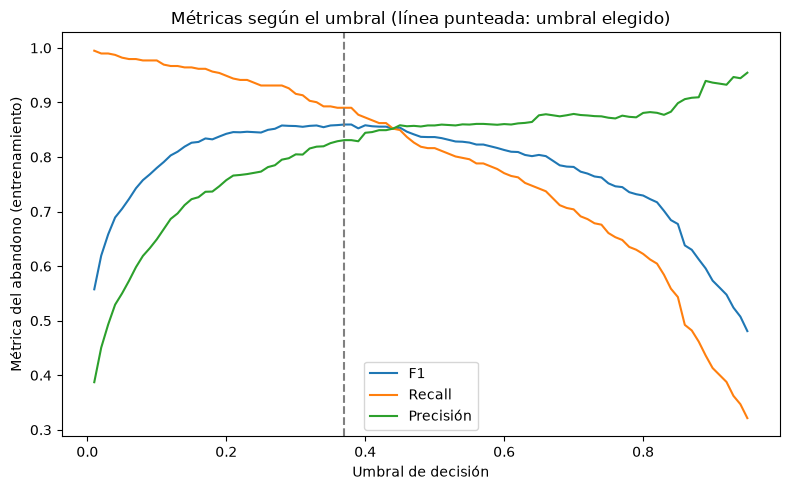

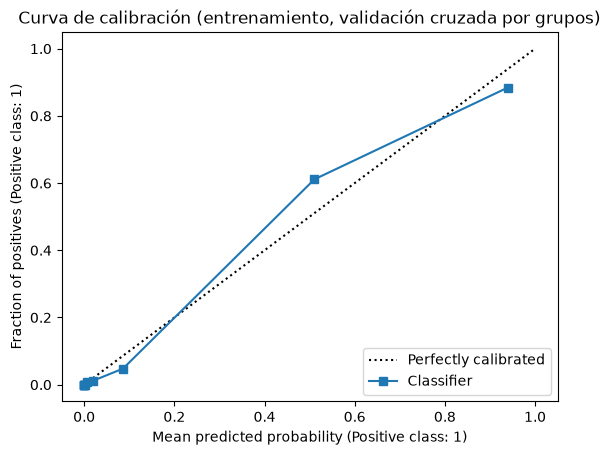

Umbral elegido: 0.37
count    2511.000
mean        0.156
std         0.309
min         0.000
25%         0.000
50%         0.003
75%         0.077
max         1.000
dtype: float64


,Umbral,F1,Recall,Precision
37,0.38,0.860,0.890,0.831
36,0.37,0.860,0.890,0.831
35,0.36,0.859,0.890,0.829
39,0.40,0.858,0.872,0.844
34,0.35,0.858,0.893,0.825
32,0.33,0.858,0.901,0.819
27,0.28,0.858,0.931,0.795
28,0.29,0.857,0.926,0.798


In [10]:
tabla_umbrales = resultado_final["tabla_umbrales"]

plt.figure(figsize=(8, 5))
plt.plot(tabla_umbrales["Umbral"], tabla_umbrales["F1"], label="F1")
plt.plot(tabla_umbrales["Umbral"], tabla_umbrales["Recall"], label="Recall")
plt.plot(tabla_umbrales["Umbral"], tabla_umbrales["Precision"], label="Precisión")
plt.axvline(umbral, linestyle="--", color="gray")
plt.xlabel("Umbral de decisión")
plt.ylabel("Métrica del abandono (entrenamiento)")
plt.title("Métricas según el umbral (línea punteada: umbral elegido)")
plt.legend()
plt.tight_layout()
plt.savefig(RUTA_FIGURAS + "04_f1_recall_precision_vs_umbral.png", bbox_inches="tight", dpi=150)
plt.show()

CalibrationDisplay.from_predictions(y_train, probabilidades_cv, n_bins=10, strategy="quantile")
plt.title("Curva de calibración (entrenamiento, validación cruzada por grupos)")
plt.savefig(RUTA_FIGURAS + "04_curva_calibracion_cv.png", bbox_inches="tight", dpi=150)
plt.show()

print("Umbral elegido:", umbral)
print(pd.Series(probabilidades_cv).describe().round(3))
tabla_umbrales.sort_values("F1", ascending=False).head(8).round(3)

**Lo que notamos.** El umbral elegido con entrenamiento es **0,37**, con un F1 de 0,860, recall de 0,890 y precisión de 0,831. La curva es plana: los ocho mejores umbrales, entre 0,28 y 0,40, dan un F1 de entre 0,857 y 0,860, así que el valor exacto no es crítico. Bajarlo hacia 0,28 sube el recall a 0,931 casi sin perder F1 (0,858), a costa de precisión (0,795); es una decisión de negocio, según cuánto cueste contactar a un cliente que no se iba a ir frente a perder uno que sí.

Las probabilidades calibradas tienen una media de 0,156, igual a la proporción real de abandono (0,1561). La mayoría de los clientes recibe una probabilidad casi cero (mediana de 0,003 y percentil 75 en 0,077) y unos pocos reciben una cercana a 1: el modelo separa bien a los clientes.

## Evaluación en prueba

Aquí abrimos `test.csv` por primera vez. El modelo, el calibrador y el umbral ya están congelados: no se ajusta nada con prueba. Calculamos las probabilidades calibradas, aplicamos el umbral de entrenamiento y reportamos las métricas junto con una línea base que siempre dice "permanece".

Como la prueba tiene pocos abandonos, damos también un intervalo del 95 % por **bootstrap por grupos**: remuestreamos perfiles completos (no filas sueltas) y recalculamos las métricas muchas veces, para ver cuánto podría moverse el resultado solo por la composición de la muestra.

In [11]:
test = pd.read_csv(RUTA_DATOS + "test.csv")
X_test = test[columnas_entrada]
y_test = test["abandono"]
assert list(test.drop(columns="abandono").columns) == columnas_entrada
assert test.isna().sum().sum() == 0

probabilidades_test = predecir_probabilidad(resultado_final, X_test)
y_pred = (probabilidades_test >= umbral).astype(int)

print("Filas de prueba:", len(test), "| abandonos:", int(y_test.sum()))
print(classification_report(y_test, y_pred, target_names=["Permanece", "Abandona"], zero_division=0))
verdaderos_negativos, falsos_positivos, falsos_negativos, verdaderos_positivos = confusion_matrix(y_test, y_pred).ravel()
print("Abandonos detectados:", verdaderos_positivos, "de", int(y_test.sum()), "| no detectados:", falsos_negativos)
print("Falsas alarmas:", falsos_positivos, "de", verdaderos_negativos + falsos_positivos, "clientes que permanecen")

metricas_test = calcular_metricas(y_test, y_pred, probabilidades_test)
print(pd.Series(metricas_test).round(3))
print("Probabilidad media predicha:", round(probabilidades_test.mean(), 3), "| proporción real de abandono:", round(y_test.mean(), 3))

Filas de prueba: 639 | abandonos: 103
              precision    recall  f1-score   support

   Permanece       0.98      0.97      0.97       536
    Abandona       0.84      0.87      0.86       103

    accuracy                           0.95       639
   macro avg       0.91      0.92      0.91       639
weighted avg       0.95      0.95      0.95       639

Abandonos detectados: 90 de 103 | no detectados: 13
Falsas alarmas: 17 de 536 clientes que permanecen
F1                    0.857
Recall                0.874
Precision             0.841
ROC_AUC               0.982
Accuracy              0.953
Precision_promedio    0.933
Brier                 0.035
dtype: float64
Probabilidad media predicha: 0.15 | proporción real de abandono: 0.161


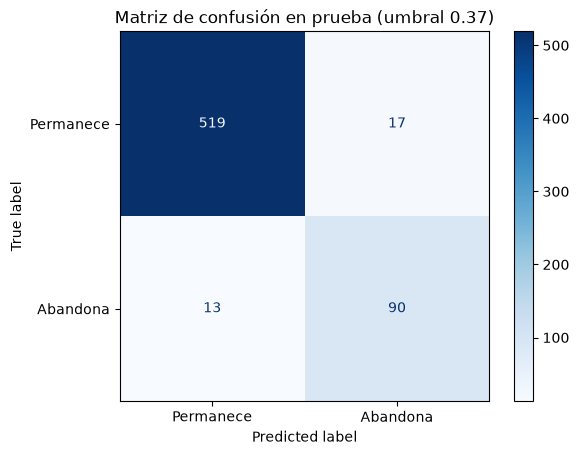

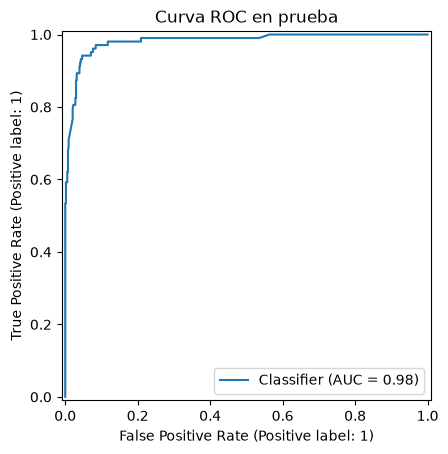

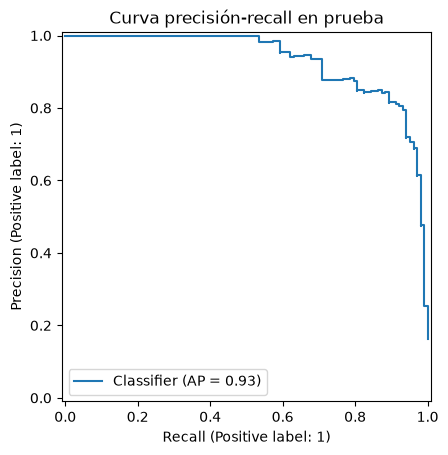

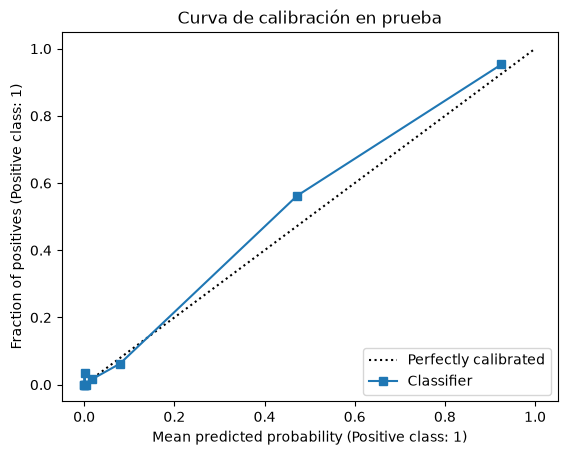

,Modelo,Accuracy,Recall,F1
0,Siempre 'permanece',0.839,0.000,0.000
1,Random Forest | class_weight | calibrado,0.953,0.874,0.857


In [12]:
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=["Permanece", "Abandona"], cmap=plt.cm.Blues)
plt.title("Matriz de confusión en prueba (umbral " + str(umbral) + ")")
plt.savefig(RUTA_FIGURAS + "04_matriz_confusion_test.png", bbox_inches="tight", dpi=150)
plt.show()

RocCurveDisplay.from_predictions(y_test, probabilidades_test)
plt.title("Curva ROC en prueba")
plt.savefig(RUTA_FIGURAS + "04_curva_roc_test.png", bbox_inches="tight", dpi=150)
plt.show()

PrecisionRecallDisplay.from_predictions(y_test, probabilidades_test)
plt.title("Curva precisión-recall en prueba")
plt.savefig(RUTA_FIGURAS + "04_curva_precision_recall_test.png", bbox_inches="tight", dpi=150)
plt.show()

CalibrationDisplay.from_predictions(y_test, probabilidades_test, n_bins=10, strategy="quantile")
plt.title("Curva de calibración en prueba")
plt.savefig(RUTA_FIGURAS + "04_curva_calibracion_test.png", bbox_inches="tight", dpi=150)
plt.show()

# Línea base: un modelo que siempre responde "permanece"
dummy = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
y_pred_dummy = dummy.predict(X_test)
comparacion = pd.DataFrame([
    {"Modelo": "Siempre 'permanece'", "Accuracy": accuracy_score(y_test, y_pred_dummy),
     "Recall": recall_score(y_test, y_pred_dummy), "F1": f1_score(y_test, y_pred_dummy, zero_division=0)},
    {"Modelo": nombre_final + " | " + estrategia_final + " | calibrado", "Accuracy": metricas_test["Accuracy"],
     "Recall": metricas_test["Recall"], "F1": metricas_test["F1"]},
])
comparacion.round(3)

**Lo que notamos.** En prueba el modelo detectó **90 de los 103 abandonos** (recall de 0,874) y dejó pasar 13. Dio 17 falsas alarmas entre los 536 clientes que permanecen (3,2 %), de modo que de sus 107 alertas 90 fueron ciertas (precisión de 0,841). El F1 fue de **0,857**, el ROC AUC de 0,982, la precisión promedio de 0,933 y el Brier de 0,035. El accuracy es 0,953, frente a 0,839 del modelo que siempre responde "permanece", que no detecta ningún abandono.

El resultado coincide con la estimación anidada de entrenamiento (0,851 ± 0,076): 0,857 cae dentro de ese rango, y no hay señal de que el resultado en prueba sea una casualidad ni de que el procedimiento esté inflado. La probabilidad media que predice es 0,150, ligeramente por debajo de la proporción real (0,161); en la curva de calibración de prueba el grupo con probabilidad media de 0,47 abandonó el 56 % de las veces, así que el modelo subestima un poco en la zona media.

In [13]:
def intervalo_bootstrap_por_grupos(y_real, probabilidades, umbral, grupos, n_remuestreos, semilla):
    """
    Calcula un intervalo del 95 % para F1, recall, precisión y precisión promedio remuestreando grupos
    (perfiles idénticos) completos con reemplazo, para no separar filas repetidas. Devuelve un DataFrame con
    el percentil 2,5 y el 97,5 de cada métrica.
    """
    y_real = np.asarray(y_real)
    grupos = np.asarray(grupos)
    generador = np.random.RandomState(semilla)
    identificadores = np.unique(grupos)
    filas_por_grupo = []
    for identificador in identificadores:
        filas_por_grupo.append(np.where(grupos == identificador)[0])

    valores = {"F1": [], "Recall": [], "Precision": [], "Precision_promedio": []}
    for remuestreo in range(n_remuestreos):
        elegidos = generador.randint(0, len(identificadores), size=len(identificadores))
        partes = []
        for posicion in elegidos:
            partes.append(filas_por_grupo[posicion])
        indices = np.concatenate(partes)
        y_muestra = y_real[indices]
        if y_muestra.sum() == 0:
            continue
        prediccion = (probabilidades[indices] >= umbral).astype(int)
        valores["F1"].append(f1_score(y_muestra, prediccion))
        valores["Recall"].append(recall_score(y_muestra, prediccion))
        valores["Precision"].append(precision_score(y_muestra, prediccion, zero_division=0))
        valores["Precision_promedio"].append(average_precision_score(y_muestra, probabilidades[indices]))

    filas = []
    for nombre_metrica in valores:
        filas.append({"Metrica": nombre_metrica,
                      "P2_5": np.percentile(valores[nombre_metrica], 2.5),
                      "P97_5": np.percentile(valores[nombre_metrica], 97.5)})
    return pd.DataFrame(filas)


def metricas_priorizacion(y_real, probabilidades, fracciones):
    """
    Mide qué pasa si contactamos solo a los clientes con mayor probabilidad: para cada fracción devuelve
    la precisión de ese grupo, el recall (qué parte de los abandonos cae dentro) y el lift frente a elegir al azar.
    """
    y_real = np.asarray(y_real)
    orden = np.argsort(-probabilidades, kind="stable")
    tasa_base = y_real.mean()
    filas = []
    for fraccion in fracciones:
        cantidad = int(np.ceil(fraccion * len(y_real)))
        seleccionados = y_real[orden[:cantidad]]
        filas.append({"Fraccion_contactada": fraccion,
                      "Clientes": cantidad,
                      "Precision": seleccionados.mean(),
                      "Recall": seleccionados.sum() / y_real.sum(),
                      "Lift": seleccionados.mean() / tasa_base})
    return pd.DataFrame(filas)


# Los grupos de la prueba se definen igual que en entrenamiento: perfiles con las mismas once entradas.
grupos_test = X_test.groupby(columnas_entrada).ngroup()
print("Perfiles distintos en prueba:", grupos_test.nunique(), "de", len(X_test), "filas")

intervalos = intervalo_bootstrap_por_grupos(y_test, probabilidades_test, umbral, grupos_test, 1000, 42)
intervalos.round(3)

Perfiles distintos en prueba: 571 de 639 filas


,Metrica,P2_5,P97_5
0,F1,0.800,0.914
1,Recall,0.800,0.933
2,Precision,0.757,0.929
3,Precision_promedio,0.881,0.968


In [14]:
priorizacion = metricas_priorizacion(y_test, probabilidades_test, [0.05, 0.10, 0.20, 0.30])
priorizacion.to_csv(RUTA_RESULTADOS + "04_priorizacion_test.csv", index=False)
priorizacion.round(3)

,Fraccion_contactada,Clientes,Precision,Recall,Lift
0,0.05,32,1.000,0.311,6.204
1,0.10,64,0.953,0.592,5.913
2,0.20,128,0.758,0.942,4.701
3,0.30,192,0.526,0.981,3.264


**Lo que notamos.** Con el bootstrap por grupos (1.000 remuestreos de los 571 perfiles distintos de prueba) el intervalo del 95 % para el F1 es de 0,800 a 0,914, para el recall de 0,800 a 0,933, para la precisión de 0,757 a 0,929 y para la precisión promedio de 0,881 a 0,968. Aun con 103 abandonos en prueba, el F1 verdadero podría estar razonablemente en cualquier punto de ese rango de unos 0,11: el 0,857 es nuestra mejor estimación, no una cifra exacta.

Para priorizar contactos, ordenar a los clientes por probabilidad funciona bien: si contactáramos solo al 10 % con mayor probabilidad (64 clientes), el 95,3 % de ellos abandonaría y capturaríamos el 59,2 % de todos los abandonos (5,9 veces más que elegir al azar); con el 20 % (128 clientes) capturaríamos el 94,2 % de los abandonos con una precisión de 0,758.

## Exportación

Guardamos el modelo final con `joblib`. Como no usamos clases propias, el archivo es un diccionario con las cuatro piezas que hacen falta para predecir: el pipeline ajustado (preprocesamiento, balanceo que solo actúa al entrenar y clasificador), el calibrador, el umbral y la lista de columnas de entrada en orden. Además guardamos una metadata en JSON con todo lo que la futura app necesitará mostrar: modelo, estrategia, hiperparámetros, umbral, las métricas anidadas y de prueba, la fecha y las versiones de las librerías.

In [15]:
artefacto = {
    "pipeline": resultado_final["pipeline"],
    "calibrador": resultado_final["calibrador"],
    "umbral": umbral,
    "columnas_entrada": columnas_entrada,
    "modelo": nombre_final,
    "estrategia_balanceo": estrategia_final,
}
joblib.dump(artefacto, RUTA_MODELOS + "modelo_final.joblib")

hiperparametros = {}
for nombre_parametro, valor in resultado_final["parametros"].items():
    hiperparametros[nombre_parametro] = str(valor)

fila_anidada = tabla_anidada.loc[posicion_final]
tabla_intervalos = {}
for i in range(len(intervalos)):
    tabla_intervalos[intervalos.loc[i, "Metrica"]] = [float(intervalos.loc[i, "P2_5"]), float(intervalos.loc[i, "P97_5"])]

metadata = {
    "modelo": nombre_final,
    "estrategia_balanceo": estrategia_final,
    "preprocesamiento": decisiones["alternativa"],
    "calibracion": "sigmoide (regresión logística sobre puntajes fuera de pliegue)",
    "columnas_entrada": columnas_entrada,
    "umbral": float(umbral),
    "hiperparametros": hiperparametros,
    "metricas_anidadas_entrenamiento": {
        "F1": float(fila_anidada["F1_anidado"]),
        "F1_desviacion": float(fila_anidada["F1_anidado_std"]),
        "Recall": float(fila_anidada["Recall_anidado"]),
        "Precision": float(fila_anidada["Precision_anidado"]),
        "Precision_promedio": float(fila_anidada["Precision_promedio"]),
        "ROC_AUC": float(fila_anidada["ROC_AUC"]),
        "Brier": float(fila_anidada["Brier"]),
    },
    "metricas_test": metricas_test,
    "intervalos_bootstrap_test_95": tabla_intervalos,
    "fecha_entrenamiento": datetime.datetime.now().isoformat(timespec="seconds"),
    "version_sklearn": sklearn.__version__,
    "version_imblearn": imblearn.__version__,
}
with open(RUTA_MODELOS + "metadata_modelo.json", "w", encoding="utf-8") as archivo:
    json.dump(metadata, archivo, indent=2, ensure_ascii=False)

print(json.dumps(metadata, indent=2, ensure_ascii=False))

{
  "modelo": "Random Forest",
  "estrategia_balanceo": "class_weight",
  "preprocesamiento": "StandardScaler",
  "calibracion": "sigmoide (regresión logística sobre puntajes fuera de pliegue)",
  "columnas_entrada": [
    "fallas_llamadas",
    "quejas",
    "antiguedad",
    "nivel_cargo",
    "segundos_uso",
    "frecuencia_uso",
    "frecuencia_sms",
    "numeros_distintos",
    "grupo_edad",
    "plan_tarifario",
    "edad"
  ],
  "umbral": 0.37,
  "hiperparametros": {
    "modelo__max_depth": "15",
    "modelo__min_samples_leaf": "1",
    "modelo__n_estimators": "400"
  },
  "metricas_anidadas_entrenamiento": {
    "F1": 0.8509451425014014,
    "F1_desviacion": 0.0758463452206477,
    "Recall": 0.882628205128205,
    "Precision": 0.8231142755106091,
    "Precision_promedio": 0.895499049109816,
    "ROC_AUC": 0.9800282430102762,
    "Brier": 0.0383467057368243
  },
  "metricas_test": {
    "F1": 0.8571428571428571,
    "Recall": 0.8737864077669902,
    "Precision": 0.8411214953271

## Cargar y verificar

Cargamos el archivo `.joblib` y comprobamos que predice **exactamente lo mismo** que el modelo que teníamos en memoria. Esto es lo que hará la app al abrirse.

In [16]:
artefacto_cargado = joblib.load(RUTA_MODELOS + "modelo_final.joblib")
puntajes_cargado = obtener_puntaje(artefacto_cargado["pipeline"], X_test[artefacto_cargado["columnas_entrada"]])
probabilidades_cargado = artefacto_cargado["calibrador"].predict_proba(puntajes_cargado.reshape(-1, 1))[:, 1]
y_pred_cargado = (probabilidades_cargado >= artefacto_cargado["umbral"]).astype(int)

print("Probabilidades idénticas:", np.array_equal(probabilidades_test, probabilidades_cargado))
print("Predicciones idénticas:", np.array_equal(y_pred, y_pred_cargado))

Probabilidades idénticas: True
Predicciones idénticas: True


**Lo que notamos.** El modelo cargado desde `modelo_final.joblib` da exactamente las mismas probabilidades y las mismas predicciones que el que teníamos en memoria. Esto es lo que hará la app al abrirse.

## Conclusiones

- **Modelo final.** Random Forest con `class_weight` (400 árboles, profundidad máxima 15, hojas mínimas de 1), escalado con `StandardScaler`, probabilidades calibradas con una curva sigmoide y umbral de 0,37 elegido con entrenamiento. Empata en la práctica con Stacking y con la red neuronal; ganó la regla y es el más rápido.
- **F1 final.** En la estimación anidada de entrenamiento, 0,851 ± 0,076; en prueba, **0,857**, con un intervalo del 95 % de 0,800 a 0,914. Detecta 90 de 103 abandonos con 17 falsas alarmas entre 536 clientes que permanecen; ROC AUC de 0,982 y Brier de 0,035.
- **Lectura prudente.** El notebook 05 repite la validación agrupando perfiles *parecidos* y no solo idénticos y el F1 baja de 0,859 a 0,811. Por eso recomendamos leer el F1 final como "entre 0,81 y 0,86": el resultado sigue siendo alto, pero una parte (unos 0,05) depende de que clientes muy parecidos puedan estar a ambos lados de la partición. El notebook 05 también confirma que no hay fuga mecánica (con etiquetas mezcladas el ROC AUC es 0,492).
- **Por qué este F1 es mucho más alto que el 0,59 del notebook 02.** Aquel número era el de una regresión logística, un modelo lineal, y aquí la regresión logística vuelve a dar entre 0,57 y 0,60. El abandono depende de interacciones (por ejemplo, quejas y uso bajo a la vez) que un modelo lineal no puede representar y los árboles sí. En el notebook 03 revisamos si la diferencia podía ser una fuga entre particiones y no encontramos evidencia: no hay duplicados exactos entre particiones y los vecinos muy cercanos no comparten etiqueta más que los demás.
- **Qué falta sobre las entradas.** El conjunto no trae fechas ni la definición exacta de varias variables, así que no podemos descartar que alguna entrada (como el uso igual a cero) ya refleje un abandono ocurrido. `Status` y `Customer Value` se dejaron fuera por trazabilidad insuficiente y no se reintrodujeron para mejorar el F1.
- **Limitaciones.** Los datos son de una sola empresa de telecomunicaciones; no sabemos cómo se comportaría el modelo en otro periodo o mercado. Los hiperparámetros del modelo final están en el extremo de la grilla. La validación cruzada interna de Stacking no usa los grupos. El umbral de 0,37 maximiza el F1, pero el umbral adecuado depende de cuánto cueste contactar a un cliente frente a perderlo.
- **Tiempo de ejecución.** El notebook completo tarda unos 26 minutos en nuestro computador; casi todo es la validación anidada.
- **Archivos generados.** `models/modelo_final.joblib`, `models/metadata_modelo.json`, `resultados/ajuste_hiperparametros.csv`, `resultados/04_priorizacion_test.csv` y las figuras `04_*.png`.

**Siguiente paso:** la app (paso 10), con formulario y CSV, mostrando probabilidades calibradas y el ranking de riesgo.